# DSCI 552 — Homework 6

### 1. Tree-Based Methods
#### (a) Download and Load the APS Failure Dataset

In [13]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
DATA_DIR = Path("data")

pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")

print("Current working directory:", Path.cwd())
print("Data folder exists:", DATA_DIR.exists())

Current working directory: /Users/bt/Documents/DSCI 552/Homework 6
Data folder exists: True


In [14]:
# Load the provided training and test sets.
train_df = pd.read_csv(
    DATA_DIR / "aps_failure_training_set.csv",
    skiprows=20,
    na_values="na"
)

test_df = pd.read_csv(
    DATA_DIR / "aps_failure_test_set.csv",
    skiprows=20,
    na_values="na"
)

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)

display(train_df.head())

Training shape: (60000, 171)
Test shape: (16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


In [15]:
# Check that the feature columns match and are numeric.
print("Columns match:", train_df.columns.equals(test_df.columns))

print(
    "Number of numeric features:",
    train_df.drop(columns="class").select_dtypes(include="number").shape[1]
)

print("Missing training values:", train_df.isna().sum().sum())
print("Missing test values:", test_df.isna().sum().sum())

Columns match: True
Number of numeric features: 170
Missing training values: 850015
Missing test values: 228680


#### (b) Data Preparation
This data set has missing values. When the number of data with missing values is significant, discarding them is not a good idea.

##### (i) Research what types of techniques are used for dealing with data with missing values
After researching, imputation is the most common method where we estimate the missing value. Usually replacing them with the median and scikit-learn has implementations in the package that help with this. It preserves all observations.

In [17]:
from sklearn.impute import SimpleImputer

# Separate predictors from the target.
# Keep these original predictors for later cross-validation pipelines.
x_train = train_df.drop(columns="class").copy()
x_test = test_df.drop(columns="class").copy()

# Encode APS failure as the positive class.
y_train = train_df["class"].map({"neg": 0, "pos": 1})
y_test = test_df["class"].map({"neg": 0, "pos": 1})

# Learn feature medians from the training data only.
imputer = SimpleImputer(strategy="median")

x_train_imputed = pd.DataFrame(
    imputer.fit_transform(x_train),
    columns=x_train.columns,
    index=x_train.index
)

# Fill test values using the medians already learned.
x_test_imputed = pd.DataFrame(
    imputer.transform(x_test),
    columns=x_test.columns,
    index=x_test.index
)

print("Missing training values:", x_train_imputed.isna().sum().sum())
print("Missing test values:", x_test_imputed.isna().sum().sum())
print("Training feature shape:", x_train_imputed.shape)
print("Test feature shape:", x_test_imputed.shape)

Missing training values: 0
Missing test values: 0
Training feature shape: (60000, 170)
Test feature shape: (16000, 170)


##### (ii) Coefficient of Variation
For each of the 170 features, I calculated the coefficient of variation:

$$
CV = \frac{s}{m}
$$

where $s$ is the sample standard deviation and $m$ is the sample mean. The calculations use the median-imputed training data.

In [18]:
# Calculate the mean and sample standard deviation of each feature.
feature_means = x_train_imputed.mean()
feature_stds = x_train_imputed.std(ddof=1)

# CV is undefined when the mean is zero.
feature_cv = feature_stds / feature_means.replace(0, np.nan)

# Collect results for all 170 features.
cv_table = pd.DataFrame({
    "mean": feature_means,
    "sample_std": feature_stds,
    "cv": feature_cv
})

cv_table.index.name = "feature"
cv_table = cv_table.sort_values("cv", ascending=False)

display(cv_table)

print("Number of features:", len(cv_table))
print("Features with undefined CV:", cv_table["cv"].isna().sum())

,mean,sample_std,cv
feature,,,
cf_000,1.431075e+05,3.504525e+07,244.887517
co_000,1.433300e+05,3.504525e+07,244.507385
ad_000,1.434383e+05,3.504525e+07,244.322816
cs_009,7.705097e+02,1.833278e+05,237.930554
dh_000,4.392641e+03,5.412441e+05,123.216097
...,...,...,...
bo_000,3.258947e+05,2.582334e+05,0.792383
bp_000,3.420739e+05,2.577156e+05,0.753392
bq_000,3.573117e+05,2.567407e+05,0.718534


Number of features: 170
Features with undefined CV: 0


##### (iii) Feature Correlation Matrix
Plot a correlation matrix for x_train_imputed dataset features

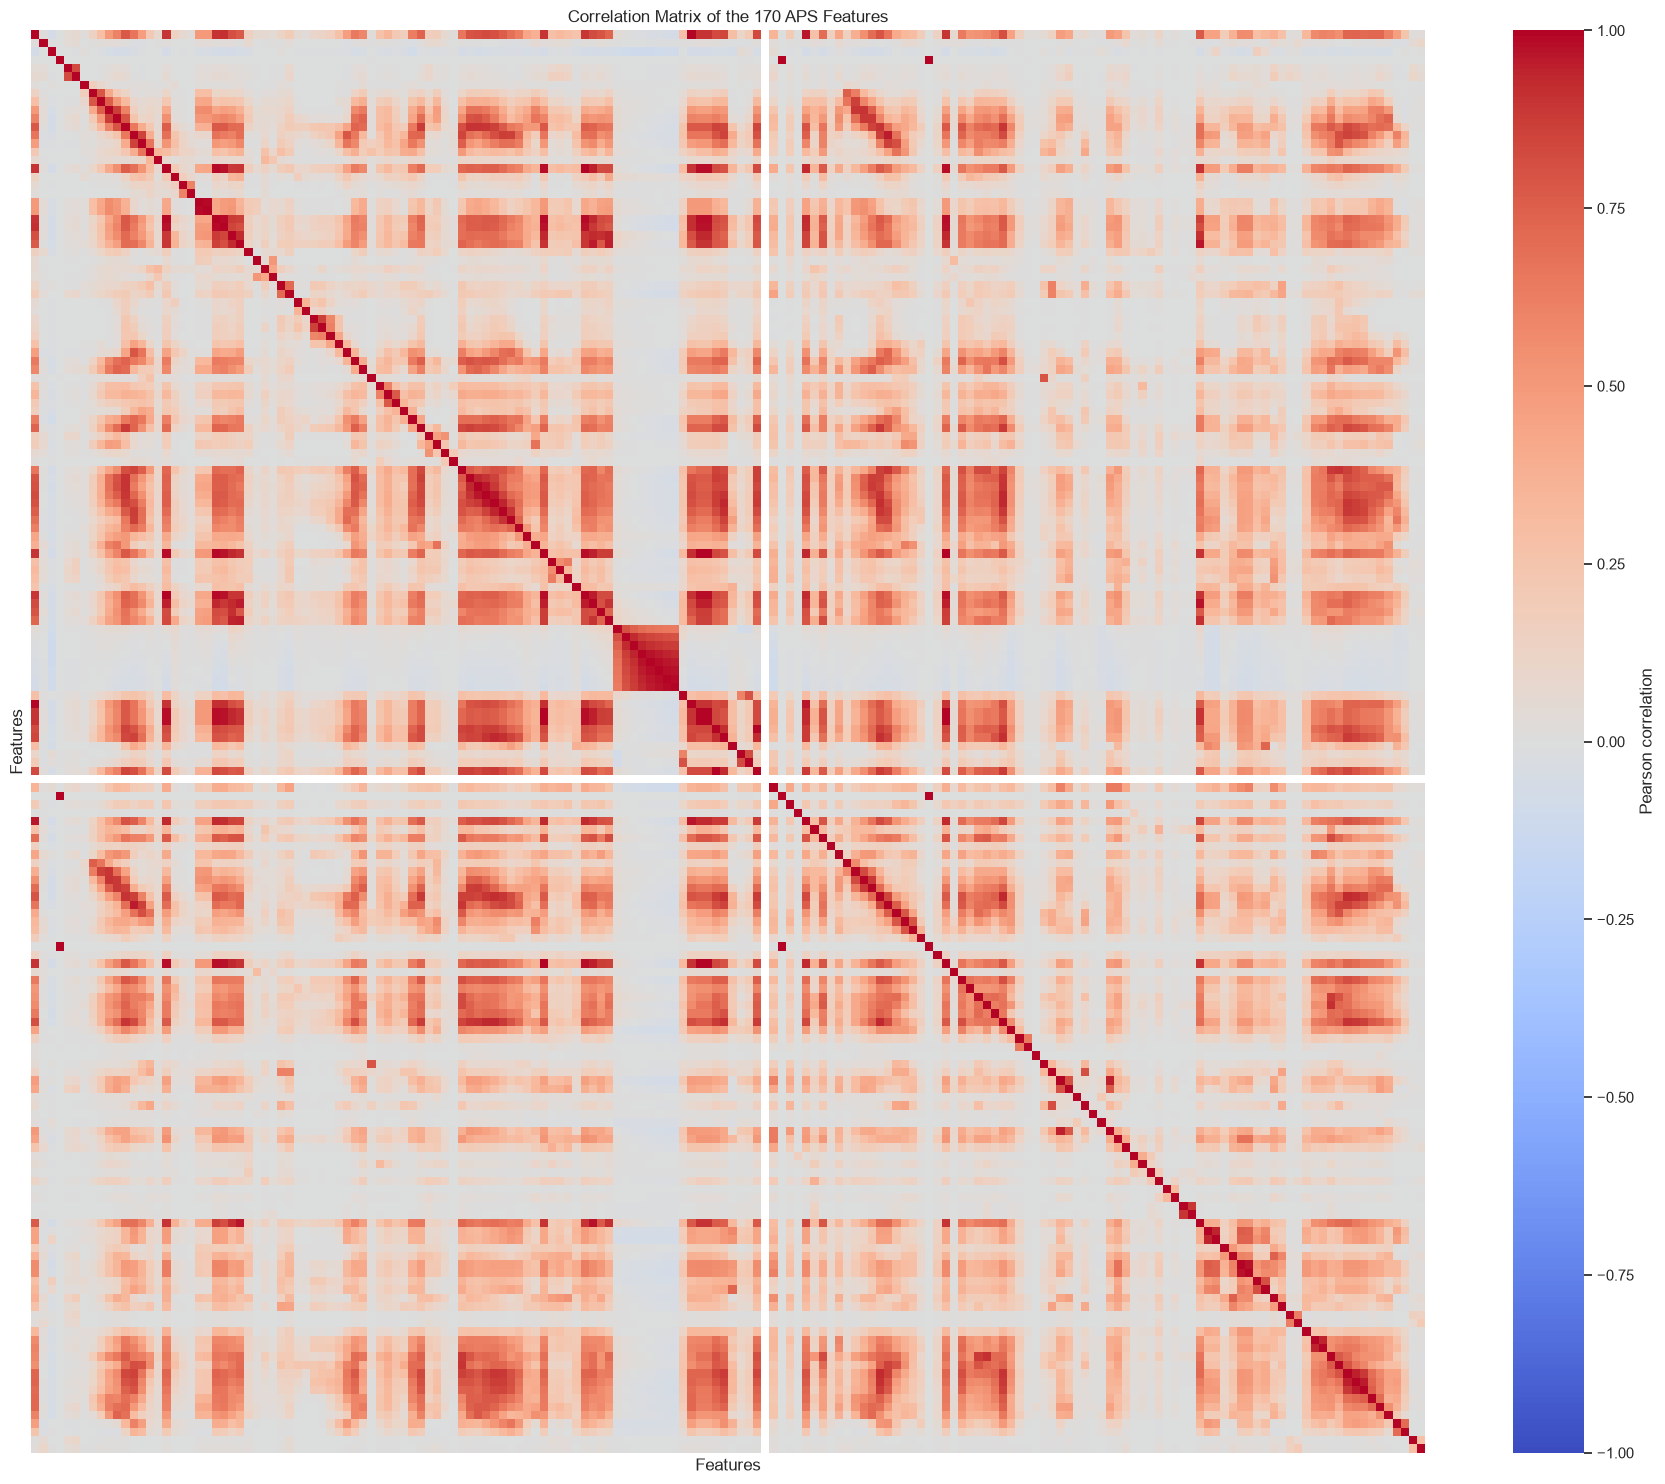

In [19]:
# Calculate correlations using the imputed training features.
correlation_matrix = x_train_imputed.corr()

plt.figure(figsize=(18, 15))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=False,
    yticklabels=False,
    cbar_kws={"label": "Pearson correlation"}
)

plt.title("Correlation Matrix of the 170 APS Features")
plt.xlabel("Features")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

The heatmap shows Pearson correlations between the 170 features, calculated using the median-imputed training data. The relevant red indicates positive correlation where as the none existed blue indicates negative correlation. Each nonconstant feature has a correlation of 1 with itself, producing the main diagonal. There are a decent amount of strong positive correlations which could explain that there are some predictive coefficients that have overlapping information.

##### (iv) Pick features with high CV and Create Scatterplot and Boxplots
First we need to pick sqrt 170 features

In [20]:
n_selected = int(np.sqrt(x_train_imputed.shape[1]))

top_features = (
    cv_table["cv"]
    .dropna()
    .nlargest(n_selected)
    .index
    .tolist()
)

print("Number of selected features:", n_selected)
display(cv_table.loc[top_features])

Number of selected features: 13


,mean,sample_std,cv
feature,,,
cf_000,143107.534133,3.504525e+07,244.887517
co_000,143330.017733,3.504525e+07,244.507385
ad_000,143438.292067,3.504525e+07,244.322816
cs_009,770.509700,1.833278e+05,237.930554
dh_000,4392.640833,5.412441e+05,123.216097
dj_000,37.271333,4.379166e+03,117.494225
ag_000,219.157733,2.036364e+04,92.917755
as_000,125.407900,1.095219e+04,87.332500
ay_009,1149.619633,9.741156e+04,84.733735


Created Scatter Plots and Box Plots

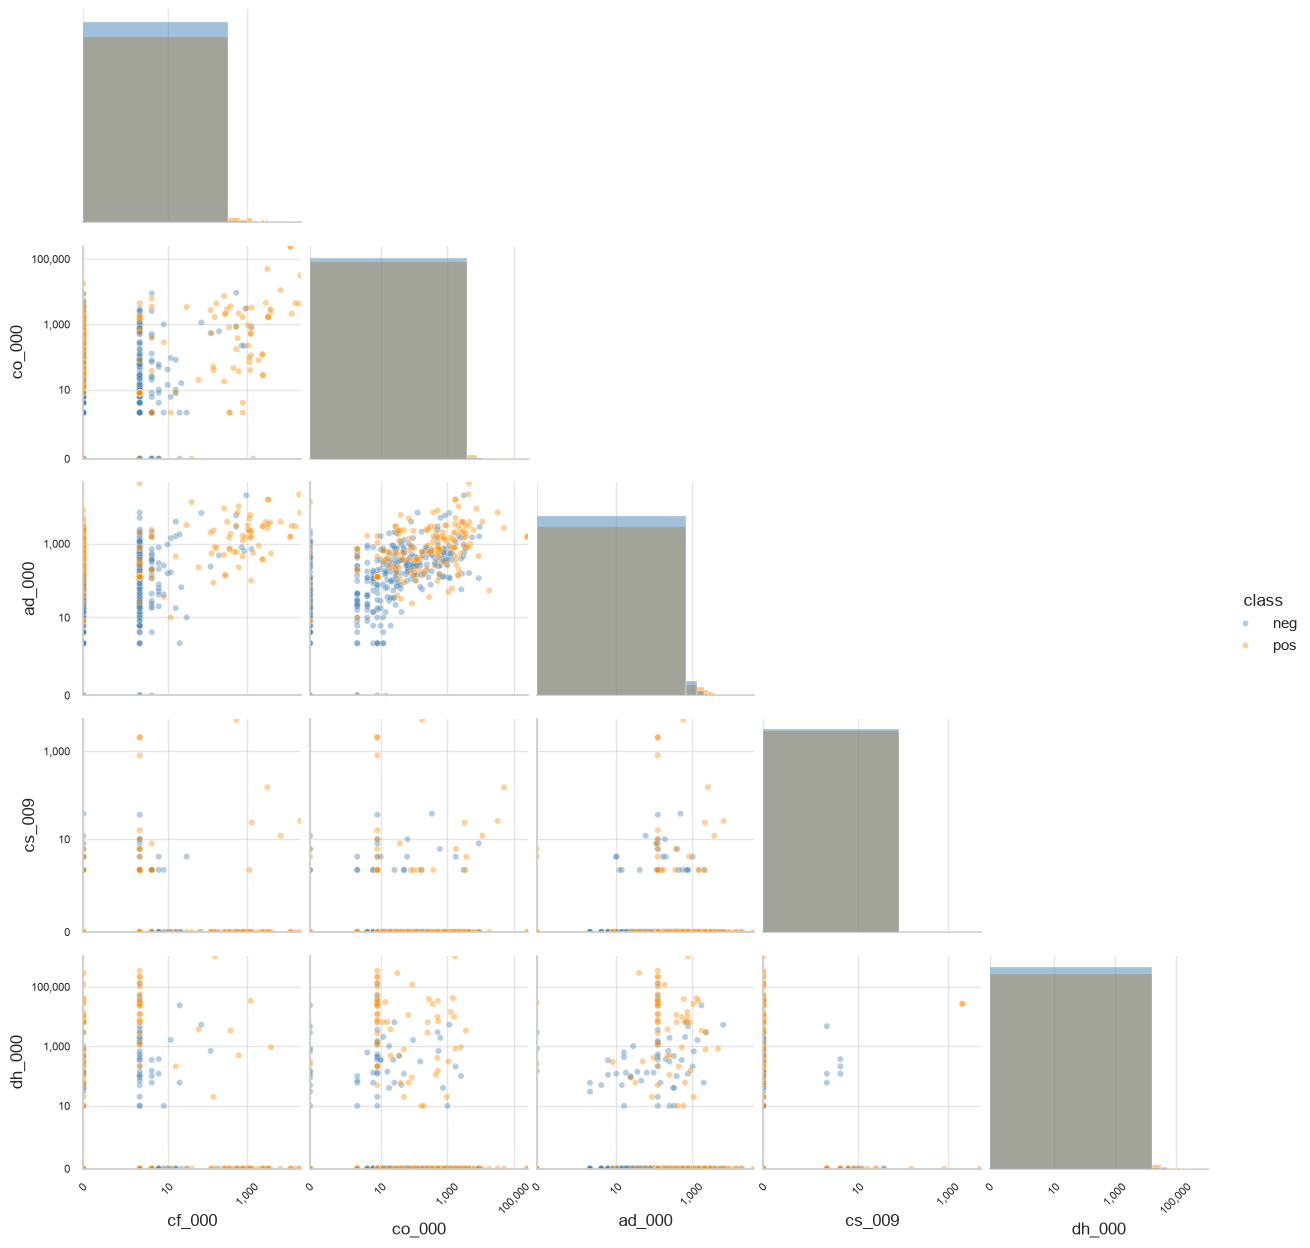

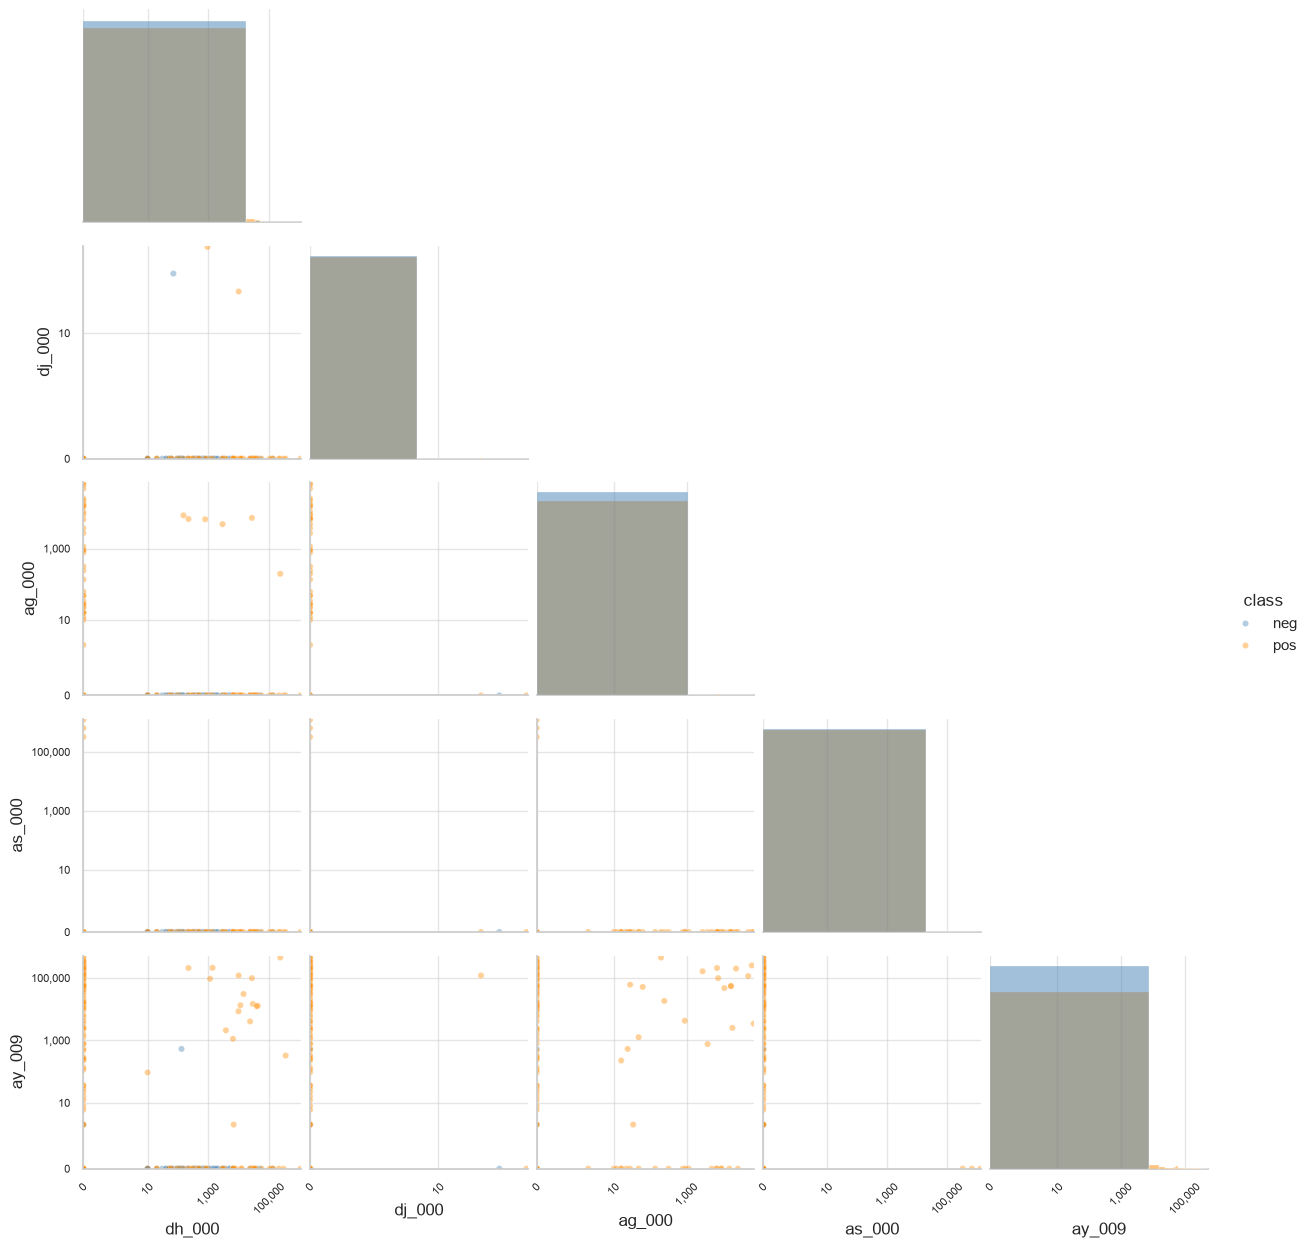

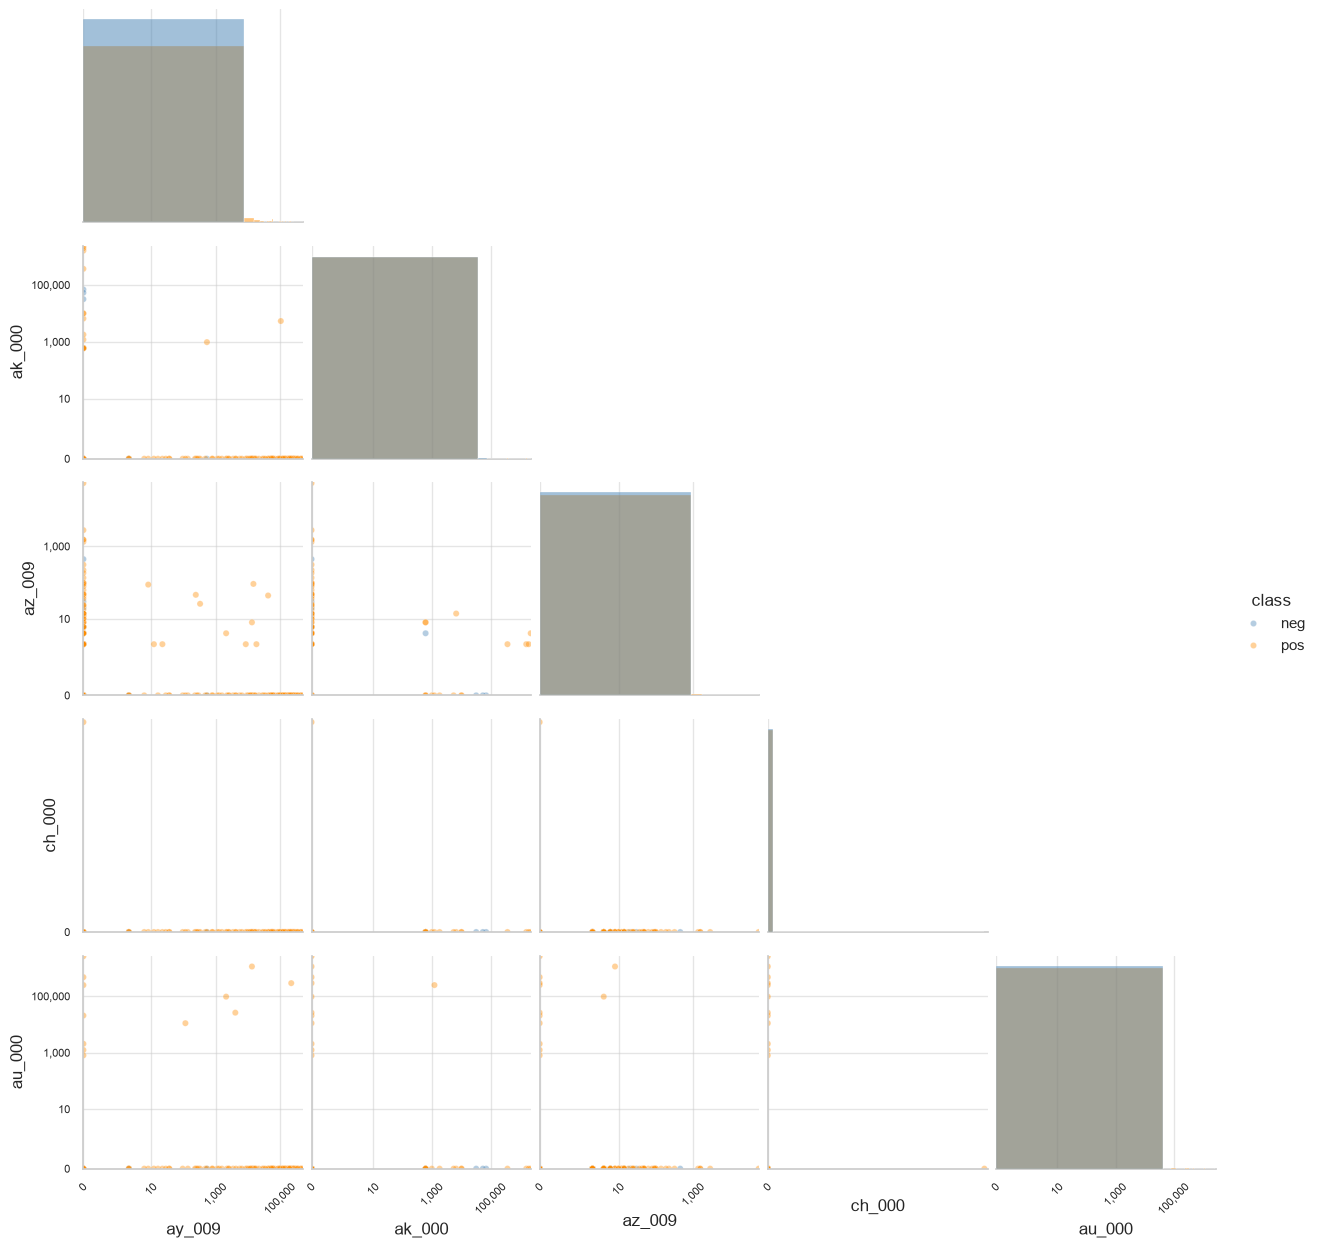

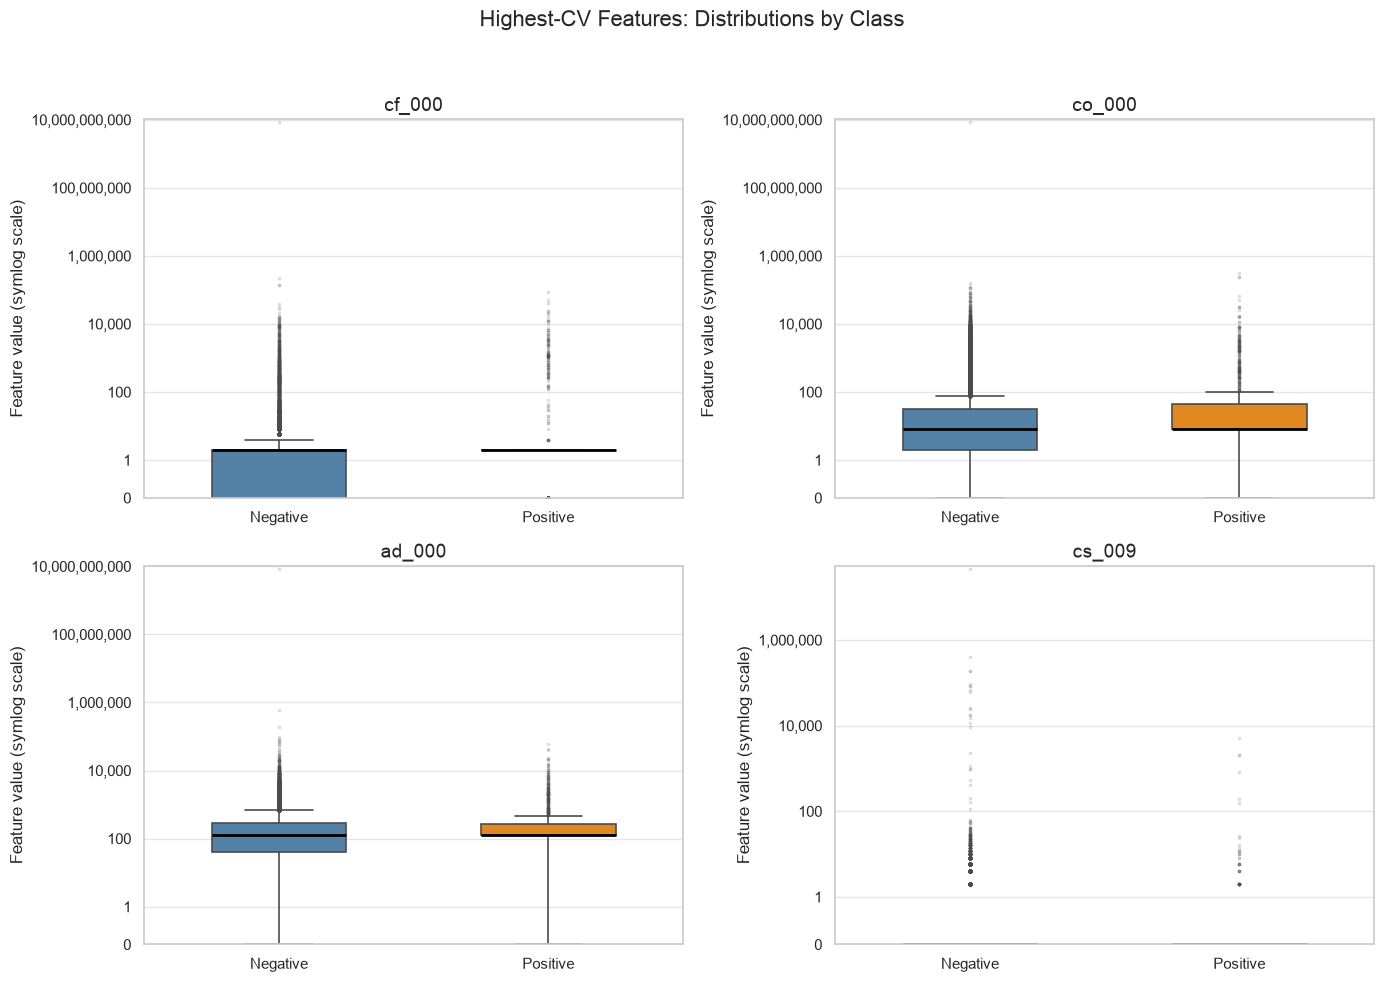

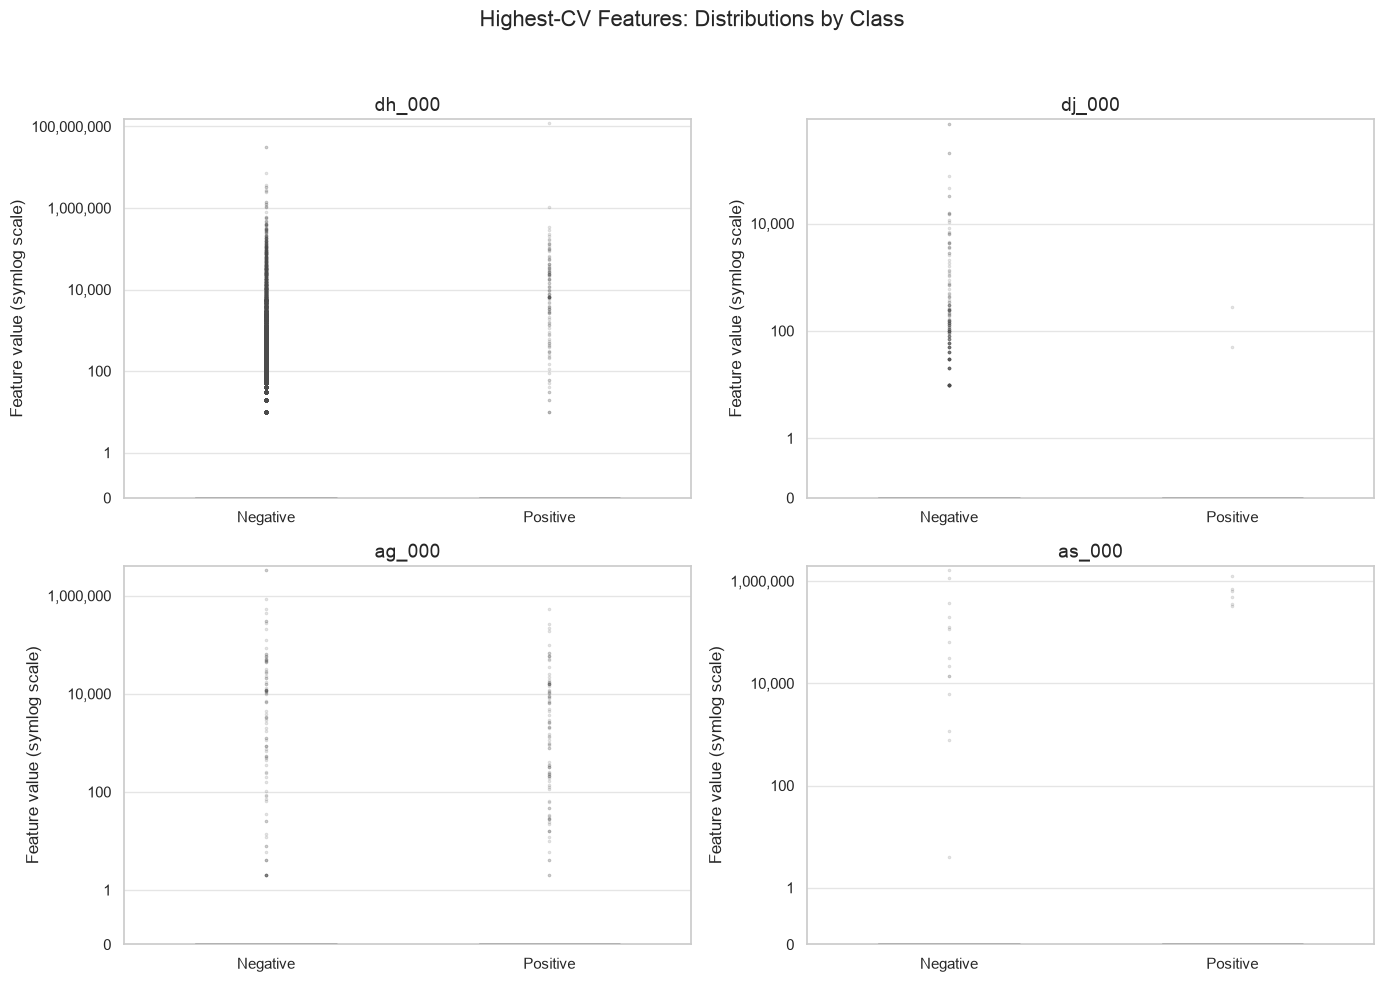

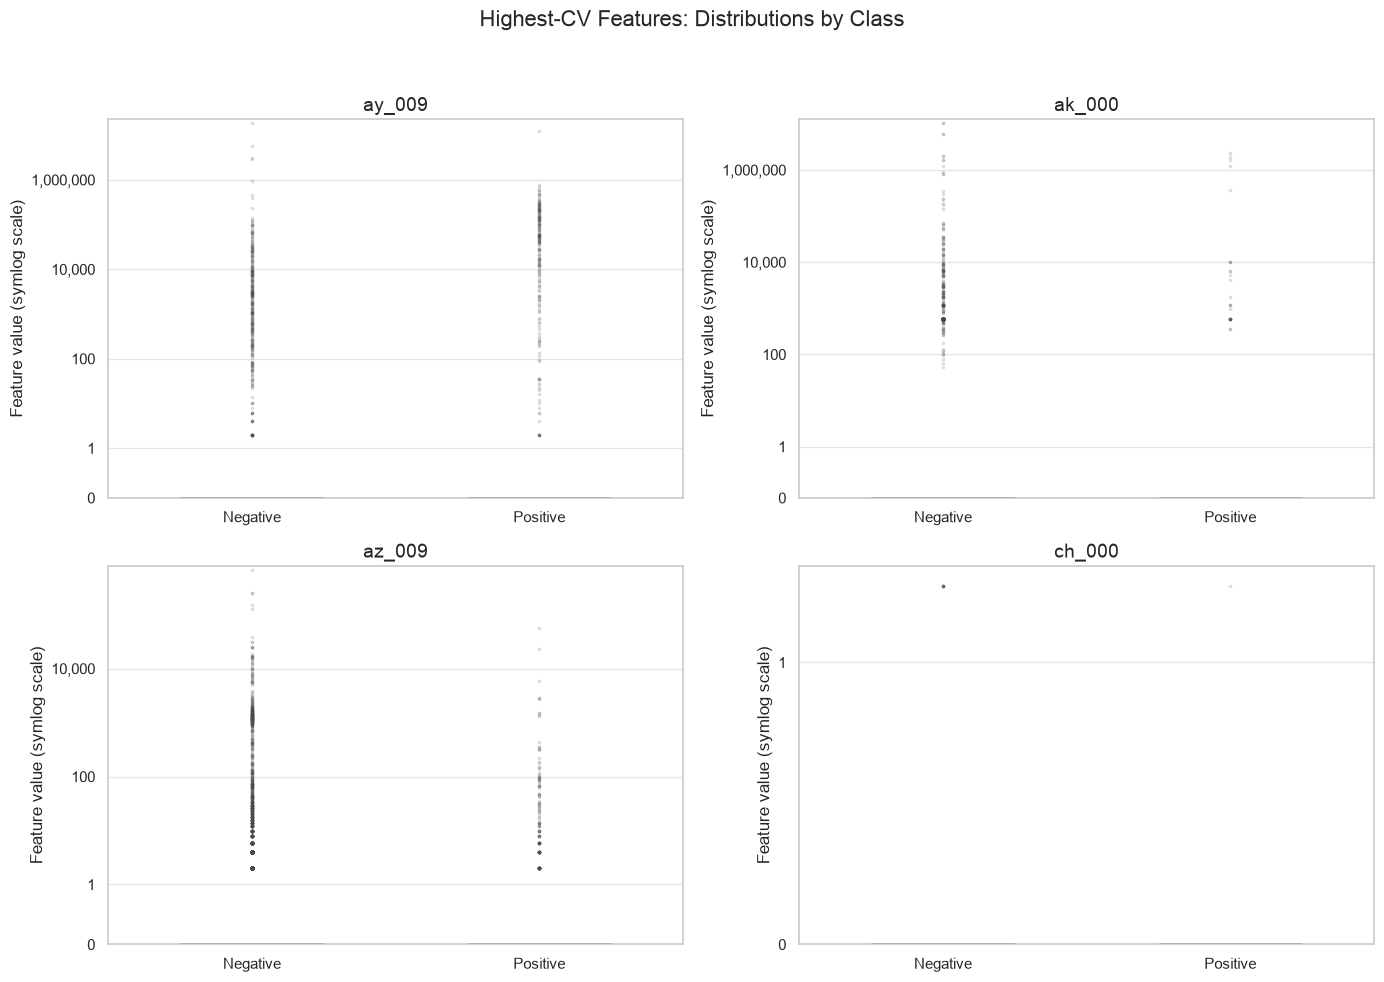

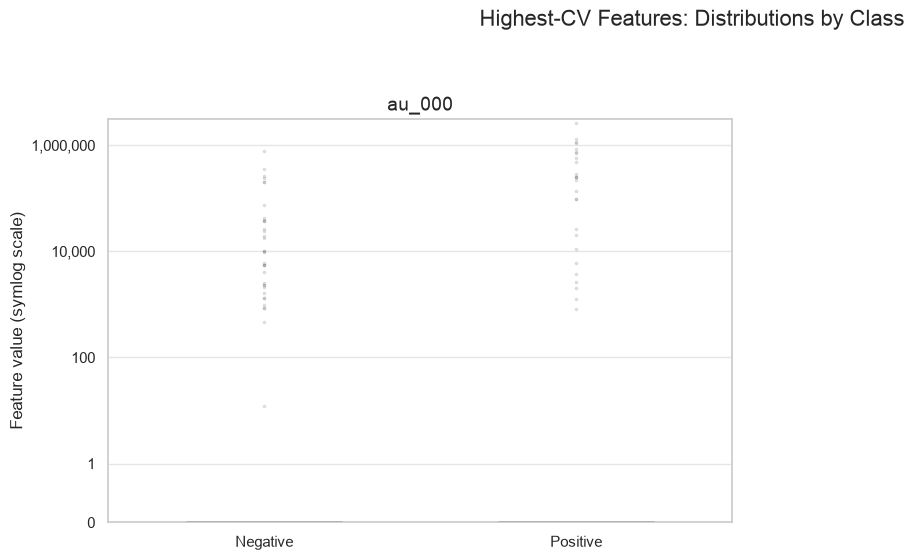

In [27]:
# Overlapping groups cover all 13 features in more readable figures.
feature_groups = [
    top_features[0:5],
    top_features[4:9],
    top_features[8:13]
]

for group_number, features in enumerate(feature_groups, start=1):
    pair_plot = sns.pairplot(
        scatter_sample,
        vars=features,
        hue="class",
        hue_order=["neg", "pos"],
        palette={"neg": "steelblue", "pos": "darkorange"},
        corner=True,
        diag_kind="hist",
        height=2.5,
        plot_kws={"s": 20, "alpha": 0.4}
    )

    # Apply the scale to feature axes, leaving histogram counts unchanged.
    from matplotlib.ticker import FixedLocator, FuncFormatter

# Display ordinary numbers instead of powers of 10.
    def format_value(value, position):
        return f"{value:,.0f}"

    ticks = [0, 10, 1_000, 100_000, 10_000_000, 1_000_000_000]

    for row, axes_row in enumerate(pair_plot.axes):
        for col, ax in enumerate(axes_row):
            if ax is not None:
                ax.set_xscale("symlog", linthresh=1)
                ax.set_xlim(left=0)
                ax.xaxis.set_major_locator(FixedLocator(ticks))
                ax.xaxis.set_major_formatter(FuncFormatter(format_value))
                ax.tick_params(axis="x", labelrotation=45, labelsize=8)

                if row != col:
                    ax.set_yscale("symlog", linthresh=1)
                    ax.set_ylim(bottom=0)
                    ax.yaxis.set_major_locator(FixedLocator(ticks))
                    ax.yaxis.set_major_formatter(FuncFormatter(format_value))
                    ax.tick_params(axis="y", labelsize=8)

    plt.show()

from matplotlib.ticker import FixedLocator, FuncFormatter

class_colors = {"neg": "steelblue", "pos": "darkorange"}

for start in range(0, len(top_features), 4):
    features = top_features[start:start + 4]

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes = axes.ravel()

    for ax, feature in zip(axes, features):
        sns.boxplot(
            data=plot_df,
            x="class",
            y=feature,
            hue="class",
            order=["neg", "pos"],
            hue_order=["neg", "pos"],
            palette=class_colors,
            dodge=False,
            legend=False,
            width=0.5,
            linewidth=1.2,
            medianprops={"color": "black", "linewidth": 2},
            flierprops={
                "marker": ".",
                "markersize": 3,
                "alpha": 0.2
            },
            ax=ax
        )

        ax.set_yscale("symlog", linthresh=1)

        # These features are nonnegative: remove empty negative space.
        upper_limit = max(1, plot_df[feature].max() * 1.2)
        ax.set_ylim(0, upper_limit)

        # Use a few tick labels, written as ordinary numbers.
        candidate_ticks = [0, 1, 100, 10_000, 1_000_000,
                           100_000_000, 10_000_000_000]
        ticks = [value for value in candidate_ticks
                 if value <= upper_limit]

        ax.yaxis.set_major_locator(FixedLocator(ticks))
        ax.yaxis.set_major_formatter(
            FuncFormatter(lambda value, _: f"{value:,.0f}")
        )
        ax.minorticks_off()

        ax.set_title(feature, fontsize=14)
        ax.set_xlabel("")
        ax.set_xticks([0, 1])
        ax.set_xticklabels(["Negative", "Positive"])
        ax.set_ylabel("Feature value")
        ax.grid(axis="x", visible=False)

    for ax in axes[len(features):]:
        ax.set_visible(False)

    fig.suptitle(
        "Highest-CV Features: Distributions by Class",
        fontsize=16
    )
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

I selected the 13 features with the highest CV values. Many have mostly small values and a few have very large values. The positive class appears to have higher median values for `co_000` and `ad_000`. However, the two classes overlap in the plots, so these features do not clearly separate them. The plots alone cannot tell us whether a feature is a significant predictor. A high CV means a feature varies greatly compared with its mean, not that it predicts APS failure well.

#### (v) Determine Positive and Negative Data Count

In [28]:
class_counts = pd.DataFrame({
    "training_count": train_df["class"].value_counts(),
    "test_count": test_df["class"].value_counts()
}).reindex(["neg", "pos"])

class_counts["training_percent"] = (
    class_counts["training_count"] / len(train_df) * 100
)

class_counts["test_percent"] = (
    class_counts["test_count"] / len(test_df) * 100
)

display(class_counts.round(2))

,training_count,test_count,training_percent,test_percent
class,,,,
neg,59000,15625,98.33,97.66
pos,1000,375,1.67,2.34


There is a very large imbalance in the both data sets, the training set contains 59,000 negative and 1,000 positive observations. Only 1.67% are positive. The test set contains 15,625 negative and 375 positive observations.

#### (c) Train a Random Forest Classifier
Calculate the confusion matrix, ROC, AUC, and misclassification for training and test sets and report them

In [29]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300,
    class_weight=None,
    bootstrap=True,
    oob_score=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf.fit(x_train_imputed, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.

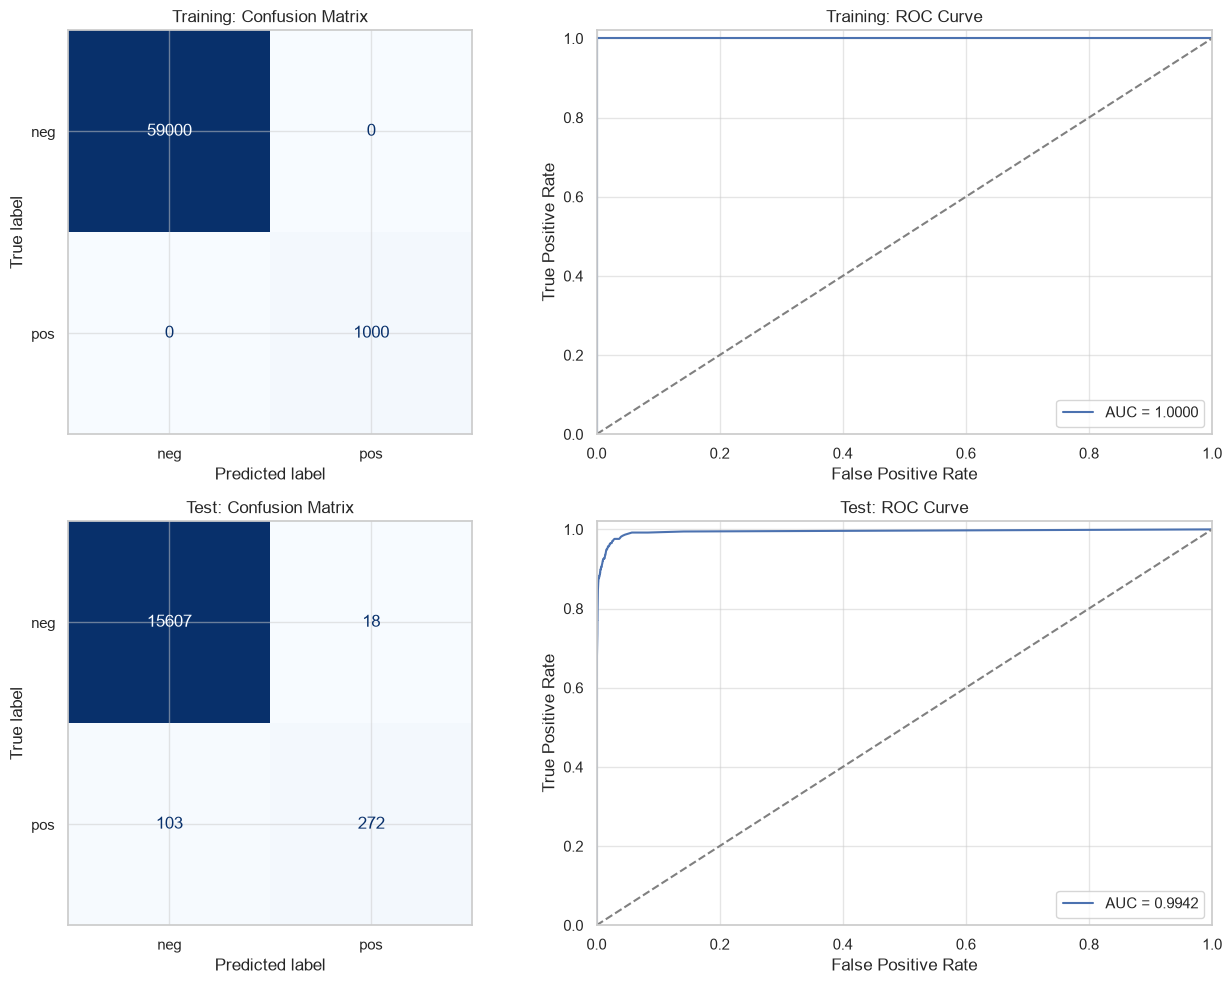

,misclassification_rate,auc
dataset,,
Training,0.0000,1.0000
Test,0.0076,0.9942


OOB error: 0.0058 (0.58%)
Test error: 0.0076 (0.76%)
OOB error minus test error: -0.0018


In [30]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

datasets = {
    "Training": (x_train_imputed, y_train),
    "Test": (x_test_imputed, y_test)
}

results = []
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for row, (name, (features, target)) in enumerate(datasets.items()):
    predictions = rf.predict(features)
    probabilities = rf.predict_proba(features)[:, 1]

    error = 1 - accuracy_score(target, predictions)
    auc = roc_auc_score(target, probabilities)

    results.append({
        "dataset": name,
        "misclassification_rate": error,
        "auc": auc
    })

    # Confusion matrix: rows are actual, columns are predicted.
    cm = confusion_matrix(target, predictions, labels=[0, 1])

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["neg", "pos"]
    ).plot(ax=axes[row, 0], cmap="Blues", colorbar=False)

    axes[row, 0].set_title(f"{name}: Confusion Matrix")

    # ROC curve.
    fpr, tpr, thresholds = roc_curve(target, probabilities)

    axes[row, 1].plot(fpr, tpr, label=f"AUC = {auc:.4f}")
    axes[row, 1].plot([0, 1], [0, 1], "--", color="gray")
    axes[row, 1].set(
        title=f"{name}: ROC Curve",
        xlabel="False Positive Rate",
        ylabel="True Positive Rate",
        xlim=(0, 1),
        ylim=(0, 1.02)
    )
    axes[row, 1].legend(loc="lower right")

plt.tight_layout()
plt.show()

rf_results = pd.DataFrame(results).set_index("dataset")
display(rf_results.round(4))

oob_error = 1 - rf.oob_score_
test_error = rf_results.loc["Test", "misclassification_rate"]

print(f"OOB error: {oob_error:.4f} ({oob_error:.2%})")
print(f"Test error: {test_error:.4f} ({test_error:.2%})")print(f"OOB error minus test error: {oob_error - test_error:.4f}")

The training misclassification rate was 0%, with an AUC of 1.0000. The test misclassification rate was approximately 0.76%, with an AUC of 0.9942.

On the test set, the model correctly classified 15,607 negative and 272 positive observations. It incorrectly flagged 18 negative observations as positive and missed 103 actual APS failures.

Although the overall test error was low, the model missed 27.47% of positive observations. This shows why overall error alone can be misleading for an imbalanced dataset.

The OOB error was approximately 0.58%, compared with a test error of 0.76%. The estimates were close, although the OOB error was slightly lower.

#### (d) Addressing Class Imbalance and Testing Again
After researching, class imbalance can be addressed using class weights or balanced sampling when training the trees.

I used `class_weight="balanced"` to give positive observations more weight during training. Because the training set contains 59 negative observations for every positive observation, each positive observation receives 59 times the weight of each negative observation.

In [31]:
rf_balanced = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    bootstrap=True,
    oob_score=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_balanced.fit(x_train_imputed, y_train)

/Users/bt/Documents/DSCI 552/Homework 6/.venv/lib/python3.11/site-packages/sklearn/ensemble/_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions

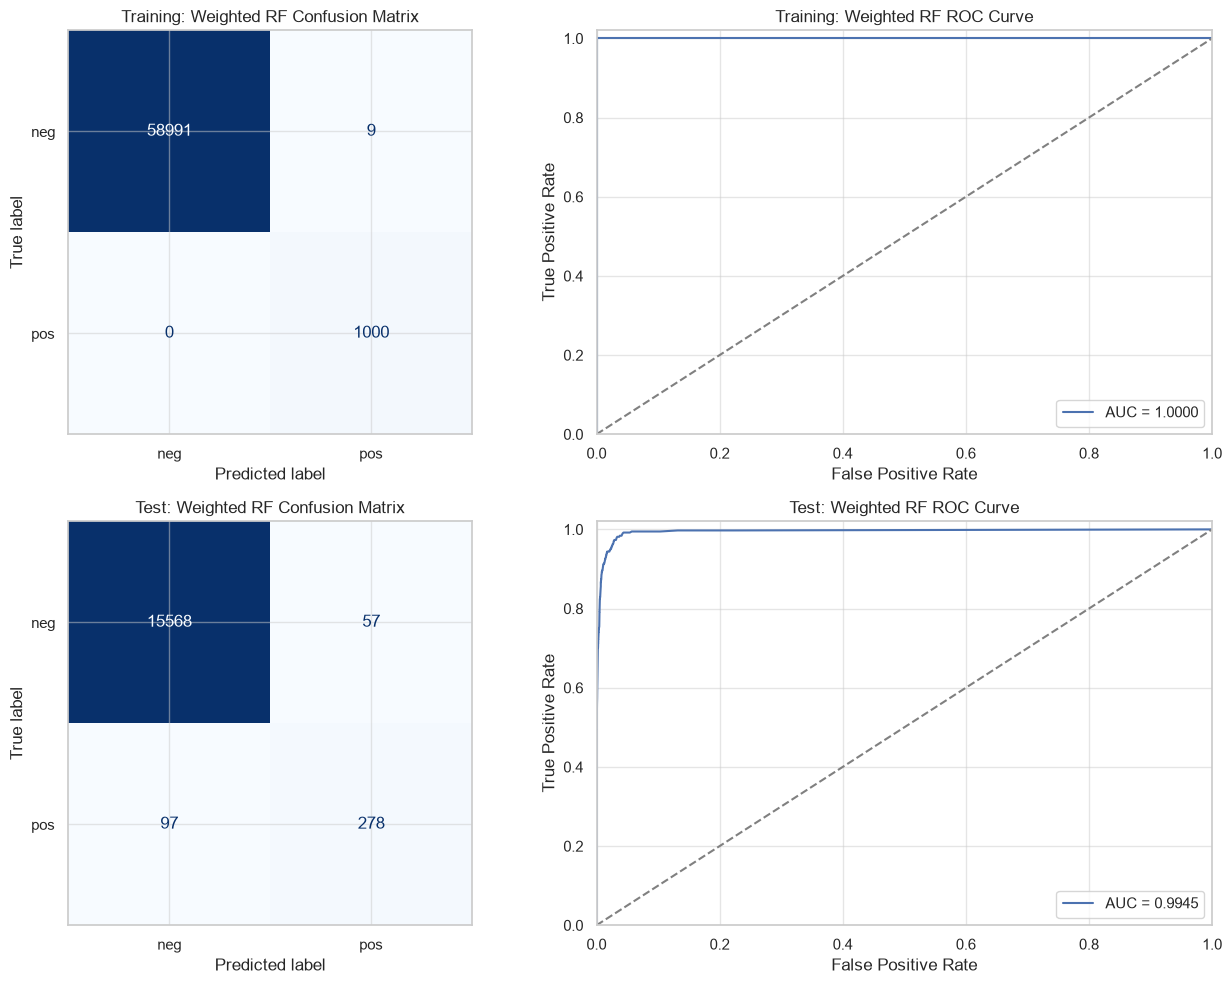

,misclassification_rate,auc
dataset,,
Training,0.0001,1.0000
Test,0.0096,0.9945


OOB error: 0.0202 (2.02%)
Test error: 0.0096 (0.96%)
OOB error minus test error: 0.0106


In [32]:
balanced_results = []
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for row, (name, (features, target)) in enumerate(datasets.items()):
    predictions = rf_balanced.predict(features)
    probabilities = rf_balanced.predict_proba(features)[:, 1]

    error = 1 - accuracy_score(target, predictions)
    auc = roc_auc_score(target, probabilities)

    balanced_results.append({
        "dataset": name,
        "misclassification_rate": error,
        "auc": auc
    })

    cm = confusion_matrix(target, predictions, labels=[0, 1])

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["neg", "pos"]
    ).plot(ax=axes[row, 0], cmap="Blues", colorbar=False)

    axes[row, 0].set_title(f"{name}: Weighted RF Confusion Matrix")

    fpr, tpr, thresholds = roc_curve(target, probabilities)

    axes[row, 1].plot(fpr, tpr, label=f"AUC = {auc:.4f}")
    axes[row, 1].plot([0, 1], [0, 1], "--", color="gray")
    axes[row, 1].set(
        title=f"{name}: Weighted RF ROC Curve",
        xlabel="False Positive Rate",
        ylabel="True Positive Rate",
        xlim=(0, 1),
        ylim=(0, 1.02)
    )
    axes[row, 1].legend(loc="lower right")

plt.tight_layout()
plt.show()

rf_balanced_results = (
    pd.DataFrame(balanced_results).set_index("dataset")
)
display(rf_balanced_results.round(4))

balanced_oob_error = 1 - rf_balanced.oob_score_
balanced_test_error = rf_balanced_results.loc[
    "Test", "misclassification_rate"
]

print(f"OOB error: {balanced_oob_error:.4f} ({balanced_oob_error:.2%})")
print(f"Test error: {balanced_test_error:.4f} ({balanced_test_error:.2%})")
print(
    "OOB error minus test error: "
    f"{balanced_oob_error - balanced_test_error:.4f}"
)

In [33]:
comparison_rows = []

for name, model in [
    ("Original RF", rf),
    ("Weighted RF", rf_balanced)
]:
    predictions = model.predict(x_test_imputed)
    probabilities = model.predict_proba(x_test_imputed)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    comparison_rows.append({
        "model": name,
        "test_error": (fp + fn) / len(y_test),
        "test_auc": roc_auc_score(y_test, probabilities),
        "positive_recall": tp / (tp + fn),
        "missed_failures": fn,
        "false_alarms": fp,
        "oob_error": 1 - model.oob_score_
    })

rf_comparison = pd.DataFrame(comparison_rows).set_index("model")
display(rf_comparison.round(4))

,test_error,test_auc,positive_recall,missed_failures,false_alarms,oob_error
model,,,,,,
Original RF,0.0076,0.9942,0.7253,103,18,0.0058
Weighted RF,0.0096,0.9945,0.7413,97,57,0.0202


The weighted random forest made 9 training errors out of 60,000
observations, giving a training error of 0.015%. Its training AUC
was 1.0 when rounded.

Compared with the original forest, positive recall increased from
72.53% to 74.13%, and missed failures decreased from 103 to 97.
However, false alarms increased from 18 to 57.

Test error increased from approximately 0.76% to 0.96%, while
test AUC increased slightly from 0.9942 to 0.9945.

The weighted forest's OOB error was 2.02%, higher than its test
error of 0.96%. The original forest's OOB error of 0.58% was
closer to its test error of 0.76%.

#### (e) XGBoost and Model Trees
First we'll set up the 5 fold validation method.

In [34]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

Import required tools and create the pipeline

In [40]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", XGBClassifier(
        booster="gblinear",
        objective="binary:logistic",
        reg_lambda=0,
        n_estimators=500,
        learning_rate=0.1,
        updater="coord_descent",
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

Try several L1 Penalties using the 5 Folds

In [41]:
alpha_grid = {
    "model__reg_alpha": [0, 0.0001, 0.001, 0.01, 0.1]
}

xgb_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=alpha_grid,
    scoring="accuracy",
    cv=cv,
    refit=True,
    n_jobs=2,
    pre_dispatch=2,
    verbose=1,
    error_score="raise"
)

# Use the original predictors so preprocessing happens inside each fold.
xgb_search.fit(x_train, y_train)

Fitting 5 folds for each of 5 candidates, totalling 25 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__reg_alpha': [0, 0.0001, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"pre_dispatch pre_dispatch: int, or str, default='2*n_jobs'Controls the number of jobs that get dispatched during parallelexecution. Reducing this number can be useful to avoid anexplosion of memory consumption when more jobs get dispatchedthan CPUs can process. This parameter can be:- None, in which case all the jobs are immediately created and spawned. Use this for lightweight and fast-running jobs, to avoid delays due to on-demand spawning of the jobs- An int, giving the exact number of total jobs that are spawned- A str, giving an expression as a function of n_jobs, as in '2*n_jobs'",2
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the 

In [42]:
cv_results = pd.DataFrame(xgb_search.cv_results_)

alpha_results = pd.DataFrame({
    "alpha": cv_results["param_model__reg_alpha"].astype(float),
    "mean_cv_error": 1 - cv_results["mean_test_score"],
    "std_cv_error": cv_results["std_test_score"]
}).sort_values("mean_cv_error")

display(alpha_results)

print("Selected alpha:", xgb_search.best_params_["model__reg_alpha"])
print(f"Selected mean CV error: {1 - xgb_search.best_score_:.4%}")

best_xgb = xgb_search.best_estimator_

,alpha,mean_cv_error,std_cv_error
3,0.0100,0.014700,1.062753e-03
0,0.0000,0.016667,1.110223e-16
1,0.0001,0.016667,1.110223e-16
2,0.0010,0.016667,1.110223e-16
4,0.1000,0.016667,1.110223e-16


Selected alpha: 0.01
Selected mean CV error: 1.4700%


Here we find out that the best alpha after testing 25 models is 0.01. Next we need to evaluate the best XGB by looking at its ROC and Confusion Matrix, as well as the CV error and Test error on Alpha 0.01.

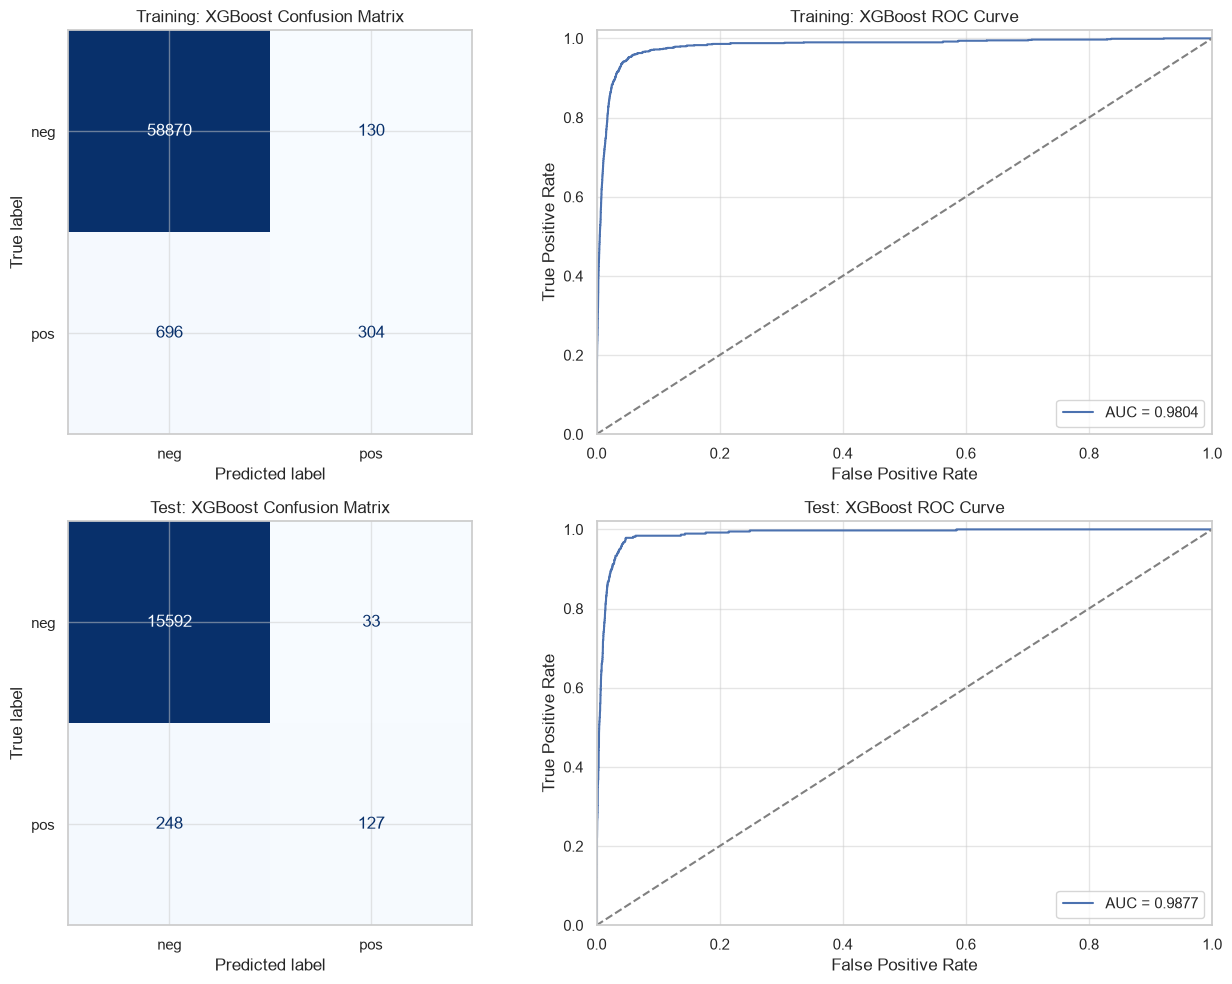

,misclassification_rate,auc,positive_recall,missed_failures,false_alarms
dataset,,,,,
Training,0.0138,0.9804,0.3040,696,130
Test,0.0176,0.9877,0.3387,248,33


Selected mean CV error: 1.47%
Test error: 1.76%


In [43]:
xgb_datasets = {
    "Training": (x_train, y_train),
    "Test": (x_test, y_test)
}

xgb_results = []
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for row, (name, (features, target)) in enumerate(xgb_datasets.items()):
    predictions = best_xgb.predict(features)
    probabilities = best_xgb.predict_proba(features)[:, 1]

    cm = confusion_matrix(target, predictions, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    xgb_results.append({
        "dataset": name,
        "misclassification_rate": (fp + fn) / len(target),
        "auc": roc_auc_score(target, probabilities),
        "positive_recall": tp / (tp + fn),
        "missed_failures": fn,
        "false_alarms": fp
    })

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["neg", "pos"]
    ).plot(ax=axes[row, 0], cmap="Blues", colorbar=False)

    axes[row, 0].set_title(f"{name}: XGBoost Confusion Matrix")

    fpr, tpr, _ = roc_curve(target, probabilities)

    axes[row, 1].plot(
        fpr, tpr,
        label=f"AUC = {roc_auc_score(target, probabilities):.4f}"
    )
    axes[row, 1].plot([0, 1], [0, 1], "--", color="gray")
    axes[row, 1].set(
        title=f"{name}: XGBoost ROC Curve",
        xlabel="False Positive Rate",
        ylabel="True Positive Rate",
        xlim=(0, 1),
        ylim=(0, 1.02)
    )
    axes[row, 1].legend(loc="lower right")

plt.tight_layout()
plt.show()

xgb_results = pd.DataFrame(xgb_results).set_index("dataset")
display(xgb_results.round(4))

print(f"Selected mean CV error: {1 - xgb_search.best_score_:.2%}")
print(
    f"Test error: "
    f"{xgb_results.loc['Test', 'misclassification_rate']:.2%}"
)

I used XGBoost's linear booster with a logistic objective and L1 regularization. I selected alpha using stratified 5-fold cross-validation without class weights or resampling. Imputation and scaling were fitted separately within each training fold.

The selected alpha was 0.01, with an average CV error of 1.47%. The training error was approximately 1.38%, and the test error was approximately 1.76%. Test error was about 0.29 percentage points higher than CV error.

Training AUC was 0.9804, and test AUC was 0.9877. On the test set, the model detected 127 of 375 APS failures, missed 248 failures, and produced 33 false alarms.

Although test AUC was high, positive recall was only 33.87%. This means the model ranked observations well but missed many failures at the default classification threshold.

Compared with both random forests, this model had higher test error, lower test AUC, and lower positive recall.

#### (f) Train XGBoost with SMOTE
First I need to import SMOTE

In [45]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import clone

Make the pipeline again

In [46]:
smote_pipeline = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("smote", SMOTE(
        sampling_strategy="auto",
        k_neighbors=5,
        random_state=RANDOM_STATE
    )),
    ("model", clone(xgb_pipeline.named_steps["model"]))
])

Then find alpha using 5-folds

In [47]:
smote_search = GridSearchCV(
    estimator=smote_pipeline,
    param_grid=alpha_grid,
    scoring="accuracy",
    cv=cv,
    refit=True,
    n_jobs=2,
    pre_dispatch=2,
    verbose=1,
    error_score="raise"
)

smote_search.fit(x_train, y_train)

Fitting 5 folds for each of 5 candidates, totalling 25 fits


/Users/bt/Documents/DSCI 552/Homework 6/.venv/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__reg_alpha': [0, 0.0001, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"pre_dispatch pre_dispatch: int, or str, default='2*n_jobs'Controls the number of jobs that get dispatched during parallelexecution. Reducing this number can be useful to avoid anexplosion of memory consumption when more jobs get dispatchedthan CPUs can process. This parameter can be:- None, in which case all the jobs are immediately created and spawned. Use this for lightweight and fast-running jobs, to avoid delays due to on-demand spawning of the jobs- An int, giving the exact number of total jobs that are spawned- A str, giving an expression as a function of n_jobs, as in '2*n_jobs'",2
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the 

In [48]:
smote_cv_results = pd.DataFrame(smote_search.cv_results_)

smote_alpha_results = pd.DataFrame({
    "alpha": smote_cv_results["param_model__reg_alpha"].astype(float),
    "mean_cv_error": 1 - smote_cv_results["mean_test_score"],
    "std_cv_error": smote_cv_results["std_test_score"]
}).sort_values("mean_cv_error")

display(smote_alpha_results)

print(
    "Selected alpha:",
    smote_search.best_params_["model__reg_alpha"]
)
print(
    f"Selected mean CV error: "
    f"{1 - smote_search.best_score_:.4%}"
)

best_xgb_smote = smote_search.best_estimator_

,alpha,mean_cv_error,std_cv_error
2,0.0010,0.024167,0.000693
1,0.0001,0.024417,0.001194
0,0.0000,0.024533,0.000987
3,0.0100,0.029617,0.000861
4,0.1000,0.030400,0.001114


Selected alpha: 0.001
Selected mean CV error: 2.4167%


Then evaluate models with alpha = 0.001

In [49]:
smote_cv_results = pd.DataFrame(smote_search.cv_results_)

smote_alpha_results = pd.DataFrame({
    "alpha": smote_cv_results["param_model__reg_alpha"].astype(float),
    "mean_cv_error": 1 - smote_cv_results["mean_test_score"],
    "std_cv_error": smote_cv_results["std_test_score"]
}).sort_values("mean_cv_error")

display(smote_alpha_results)

print(
    "Selected alpha:",
    smote_search.best_params_["model__reg_alpha"]
)
print(
    f"Selected mean CV error: "
    f"{1 - smote_search.best_score_:.4%}"
)

best_xgb_smote = smote_search.best_estimator_

,alpha,mean_cv_error,std_cv_error
2,0.0010,0.024167,0.000693
1,0.0001,0.024417,0.001194
0,0.0000,0.024533,0.000987
3,0.0100,0.029617,0.000861
4,0.1000,0.030400,0.001114


Selected alpha: 0.001
Selected mean CV error: 2.4167%


Here we find out that the best alpha after testing 25 models is 0.001. Next we need to evaluate the best SMOTE XGB by looking at its ROC and Confusion Matrix, as well as the CV error and Test error on Alpha 0.001.


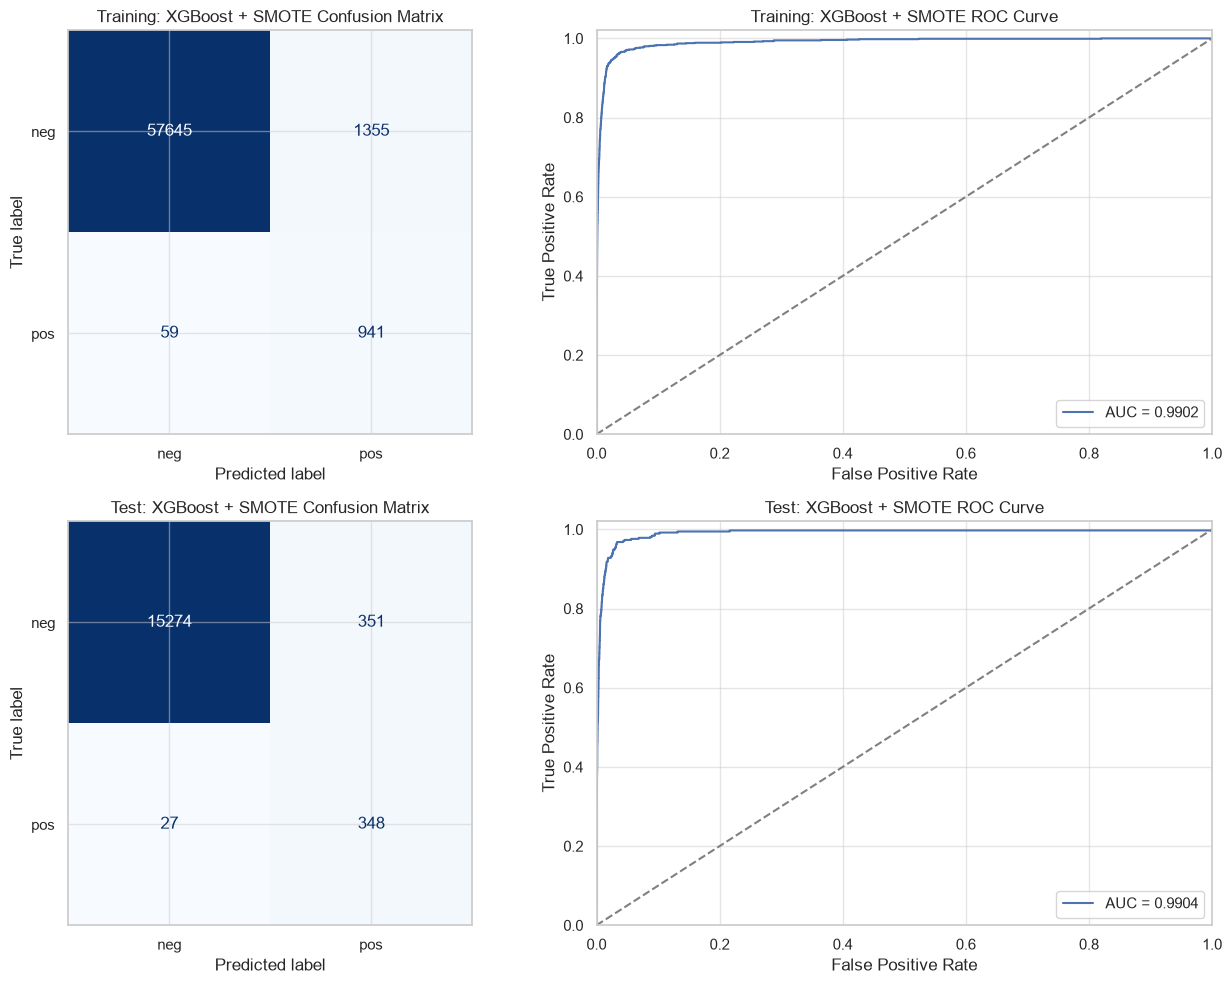

,misclassification_rate,auc,positive_recall,missed_failures,false_alarms
dataset,,,,,
Training,0.0236,0.9902,0.941,59,1355
Test,0.0236,0.9904,0.928,27,351


Selected mean CV error: 2.42%
Test error: 2.36%


In [50]:
smote_results = []
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for row, (name, (features, target)) in enumerate(xgb_datasets.items()):
    predictions = best_xgb_smote.predict(features)
    probabilities = best_xgb_smote.predict_proba(features)[:, 1]

    cm = confusion_matrix(target, predictions, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    auc = roc_auc_score(target, probabilities)

    smote_results.append({
        "dataset": name,
        "misclassification_rate": (fp + fn) / len(target),
        "auc": auc,
        "positive_recall": tp / (tp + fn),
        "missed_failures": fn,
        "false_alarms": fp
    })

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["neg", "pos"]
    ).plot(ax=axes[row, 0], cmap="Blues", colorbar=False)

    axes[row, 0].set_title(f"{name}: XGBoost + SMOTE Confusion Matrix")

    fpr, tpr, _ = roc_curve(target, probabilities)

    axes[row, 1].plot(fpr, tpr, label=f"AUC = {auc:.4f}")
    axes[row, 1].plot([0, 1], [0, 1], "--", color="gray")
    axes[row, 1].set(
        title=f"{name}: XGBoost + SMOTE ROC Curve",
        xlabel="False Positive Rate",
        ylabel="True Positive Rate",
        xlim=(0, 1),
        ylim=(0, 1.02)
    )
    axes[row, 1].legend(loc="lower right")

plt.tight_layout()
plt.show()

smote_results = pd.DataFrame(smote_results).set_index("dataset")
display(smote_results.round(4))

print(f"Selected mean CV error: {1 - smote_search.best_score_:.2%}")
print(
    f"Test error: "
    f"{smote_results.loc['Test', 'misclassification_rate']:.2%}"
)

After adding SMOTE to the linear XGBoost pipeline used in part (e). Imputation, scaling, and SMOTE were applied within each training fold.

Cross-validation selected alpha = 0.001. The average CV error was approximately 2.42%, close to the test error of 2.36%.

On the original training observations, the error was approximately 2.36%, with an AUC of 0.9902. Test AUC was 0.9904.

Compared with the model without SMOTE, test recall increased from 33.87% to 92.80%, and missed failures decreased from 248 to 27. However, false alarms increased from 33 to 351, raising the overall test error from 1.76% to 2.36%.

SMOTE helped the model detect many more APS failures, but at the cost of more false alarms.

### 2. ISLR 6.6.3
#### (a) Training RSS
Answer: iv. Steadily decrease

With a larger s, the model has more freedom to fit the training data. Training RSS therefore decreases or stays the same. Once the constraint no longer restricts the least-squares solution, training RSS stays constant.

#### (b) Test RSS
Answer: ii. Decrease initially, then increase in a U shape

Initially, greater flexibility can improve predictions by reducing underfitting. With too much flexibility, the model may fit noise in the training data, increasing test RSS. This is the expected pattern, rather than a guarantee for every dataset.

#### (c) Variance
Answer: iii. Steadily increase

As the model becomes more flexible, its predictions generally become more sensitive to changes in the training data.

#### (d) Squared Bias
Answer: iv. Steadily decrease

Relaxing the constraint lets the model capture more of the true relationship, generally reducing squared bias.

#### (e) Irreducible Error
Answer: v. Remain constant

Irreducible error comes from noise in the data. Changing s does not change that noise.

### 3. ISLR 6.6.5
#### (a) Ridge Regression Optimization Problem
The ridge coefficients minimize:

$$
(y_1-\beta_1x_{11}-\beta_2x_{12})^2
+
(y_2-\beta_1x_{21}-\beta_2x_{22})^2
+
\lambda(\beta_1^2+\beta_2^2).
$$

Because $x_{11}=x_{12}$ and $x_{21}=x_{22}$, this becomes:

$$
\min_{\beta_1,\beta_2}
\left[
(y_1-x_{11}(\beta_1+\beta_2))^2
+
(y_2-x_{21}(\beta_1+\beta_2))^2
+
\lambda(\beta_1^2+\beta_2^2)
\right].
$$

#### (b) Why the Ridge Coefficients Are Equal
For a fixed sum $t=\beta_1+\beta_2$, the RSS stays the same. However, the ridge penalty states:

$$
\beta_1^2+\beta_2^2
=
\frac{t^2}{2}
+
\frac{(\beta_1-\beta_2)^2}{2}.
$$

At $\lambda>0$, this penalty is smallest when
$\beta_1-\beta_2=0$. Therefore:

$$
\hat{\beta}_1=\hat{\beta}_2.
$$

#### (c) Lasso Regression Optimization Problem
The lasso replaces the squared-coefficient with an absolute-value:

$$
\min_{\beta_1,\beta_2}
\left[
(y_1-x_{11}(\beta_1+\beta_2))^2
+
(y_2-x_{21}(\beta_1+\beta_2))^2
+
\lambda(|\beta_1|+|\beta_2|)
\right].
$$

#### (d) Why the Lasso Coefficients May Not Be Unique
If we let $t$ be the coefficient sum. Any pair with that sum gives the same predictions and RSS. The triangle inequality gives us:

$$
|\beta_1|+|\beta_2|\geq|\beta_1+\beta_2|=|t|.
$$

Equality holds when the coefficients have the same sign, including when one is zero. Therefore, all pairs of the form

$$
\hat{\beta}_1=ut,
\qquad
\hat{\beta}_2=(1-u)t,
\qquad
0\leq u\leq1
$$

give the same minimum penalty and RSS.

For example, if $t=4$, then $(4,0)$, $(3,1)$, and $(2,2)$ are equally good solutions.

When the optimal sum is nonzero, there are many coefficient pairs that solve the lasso problem. If the
optimal sum is zero and $\lambda>0$, the solution is instead $\hat{\beta}_1=\hat{\beta}_2=0$.

### 4. ISLR 8.4.5
#### Majority Vote
Six trees estimate a probability of red greater than 0.5, so they predict red. The remaining four predict green.

Therefore, the majority-vote prediction is red.

#### Average Probability
The average estimated probability of red is:

$$
\bar{p}
=
\frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}
=0.45.
$$

Because $0.45<0.5$, the average-probability prediction is green.

### 5. ISLR 9.7.3
#### (a) Sketch out Observations

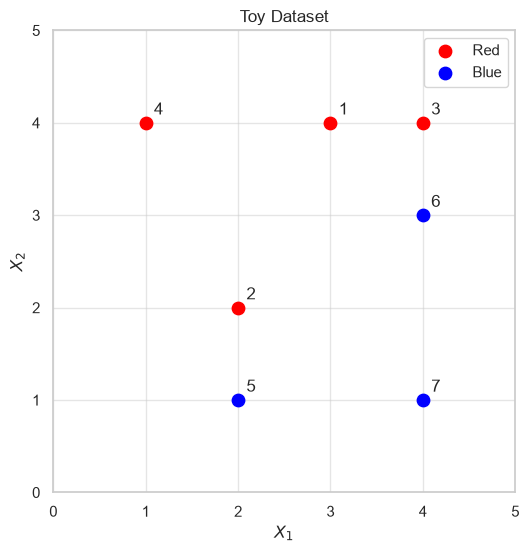

In [51]:
toy_data = pd.DataFrame({
    "x1": [3, 2, 4, 1, 2, 4, 4],
    "x2": [4, 2, 4, 4, 1, 3, 1],
    "class": ["Red", "Red", "Red", "Red", "Blue", "Blue", "Blue"]
})

def draw_observations(ax):
    for label, color in [("Red", "red"), ("Blue", "blue")]:
        group = toy_data[toy_data["class"] == label]

        ax.scatter(
            group["x1"], group["x2"],
            color=color, s=80, label=label
        )

    for number, row in enumerate(toy_data.itertuples(), start=1):
        ax.annotate(
            str(number),
            (row.x1, row.x2),
            xytext=(6, 6),
            textcoords="offset points"
        )

    ax.set(
        xlabel="$X_1$",
        ylabel="$X_2$",
        xlim=(0, 5),
        ylim=(0, 5)
    )
    ax.set_aspect("equal")
    ax.set_xticks(range(6))
    ax.set_yticks(range(6))

fig, ax = plt.subplots(figsize=(6, 6))
draw_observations(ax)
ax.set_title("Toy Dataset")
ax.legend()
plt.show()

### (b) Optimal Separating Hyperplane
The closest red points lie on $X_2=X_1$, and the closest blue points lie on $X_2=X_1-1$. The optimal separating line lies halfway between them:

$$
0.5-X_1+X_2=0.
$$

### (c) Classification Rule
Classify an observation as Red if:

$$
0.5-X_1+X_2>0,
$$

and Blue otherwise. Therefore, the possible betas are is:

$$
\beta_0=0.5,\qquad \beta_1=-1,\qquad \beta_2=1.
$$

### (d) Margin
The margin boundaries are:

$$
X_2=X_1
\qquad\text{and}\qquad
X_2=X_1-1.
$$

The perpendicular distance from the separating line to either margin boundary is:

$$
M=\frac{0.5}{\sqrt{(-1)^2+1^2}}
=\frac{1}{2\sqrt{2}}
\approx0.354.
$$

### (e) Support Vectors
The support vectors are observations **2, 3, 5, and 6**.
They lie on the margin boundaries and are closest to the
separating line.

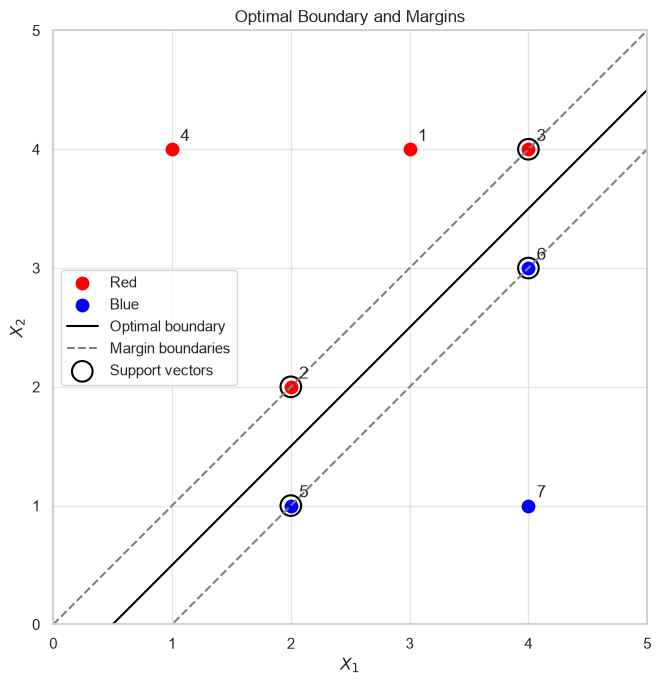

In [58]:
line_x = np.linspace(0, 5, 200)

fig, ax = plt.subplots(figsize=(7, 7))
draw_observations(ax)

ax.plot(
    line_x, line_x - 0.5,
    color="black", label="Optimal boundary"
)
ax.plot(
    line_x, line_x,
    "--", color="gray", label="Margin boundaries"
)
ax.plot(line_x, line_x - 1, "--", color="gray")

support = toy_data.loc[[1, 2, 4, 5]]

ax.scatter(
    support["x1"], support["x2"],
    s=220,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    label="Support vectors"
)

ax.set_title("Optimal Boundary and Margins")
ax.legend()
plt.tight_layout()
plt.show()

### (f) Moving Observation 7
Observation 7 is not a support vector and lies well away from
the margin. A sufficiently small movement would leave it
outside the margin, so the optimal separating line would
remain unchanged.

### (g) A Nonoptimal Separating Hyperplane
There are two possible non-optimal separating hyperplanes:

$$
X_2=X_1-0.25,
$$

or

$$
0.25-X_1+X_2=0.
$$

This line separates all observations correctly, but it is closer to the nearest red points than to the nearest blue points, there deeming it sub-optimal.

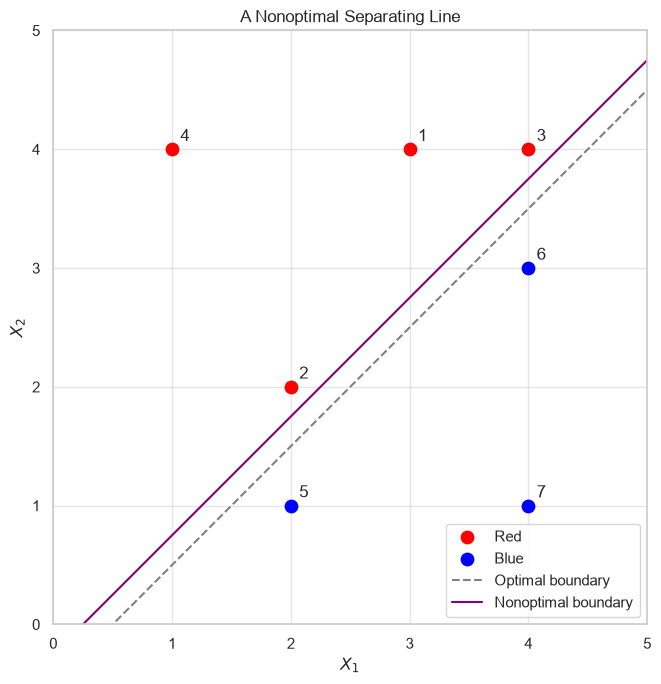

In [59]:
line_x = np.linspace(0, 5, 200)

fig, ax = plt.subplots(figsize=(7, 7))
draw_observations(ax)

ax.plot(
    line_x, line_x - 0.5,
    "--", color="gray", label="Optimal boundary"
)
ax.plot(
    line_x, line_x - 0.25,
    color="purple", label="Nonoptimal boundary"
)

ax.set_title("A Nonoptimal Separating Line")
ax.legend()
plt.tight_layout()
plt.show()

### (h) Making the Classes Nonseparable
This point lies halfway between the Red observations $(2,2)$ and $(4,4)$. Any straight line placing both red points strictly on one side must also place their midpoint on that side. Therefore, no straight line can separate all red and blue observations.

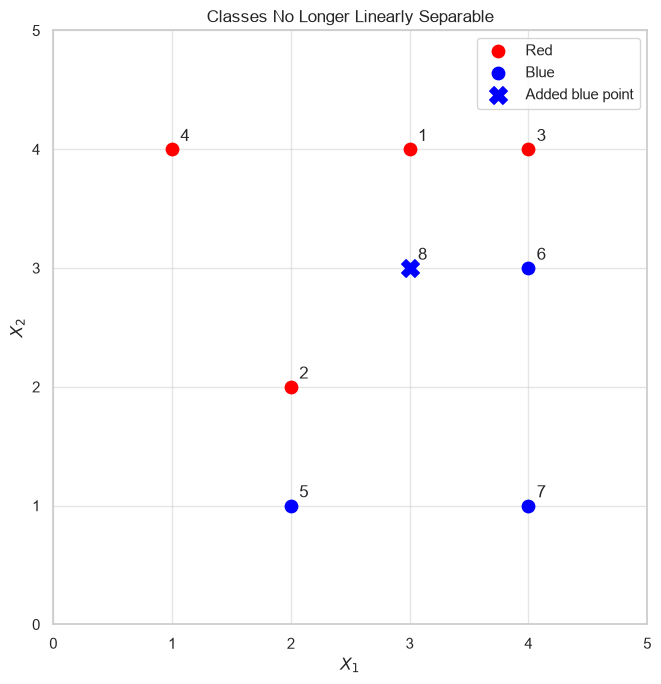

In [60]:
fig, ax = plt.subplots(figsize=(7, 7))
draw_observations(ax)

ax.scatter(
    3, 3,
    color="blue",
    marker="X",
    s=160,
    label="Added blue point"
)

ax.annotate(
    "8",
    (3, 3),
    xytext=(6, 6),
    textcoords="offset points"
)

ax.set_title("Classes No Longer Linearly Separable")
ax.legend()
plt.tight_layout()
plt.show()